In [1]:
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas
from dataframe_modify.add_context import add_context
from get_data.get_data import get_merged_events
from get_data.get_data import get_sb360

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

frames = get_sb360(MATCH_ID)
events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)
start_team = events['possession_team'][0]

events = add_context(events, frames)
events = add_positions(events)
events = swap_y(events)
events = generalize_perspective(events, start_team)
events = add_grid_areas(events)

In [2]:
from sequences.get_sequences import get_sequences_by_possession

sequences = get_sequences_by_possession(events)
sequences[0]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,context_locations,teammate_locations,actor_locations,start_x,start_y,end_x,end_y,start_area,end_area,area_code
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,"[[36.265689298764926, 42.66252357107007], [43....","[True, True, True, False, True, True, True, Fa...","[False, False, False, False, False, False, Tru...",60.0,40.0,36.1,40.3,F5,D4,F5D4
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,"[[83.9000015258789, 39.70000076293945], [76.13...","[True, True, True, False, False, True, True, T...","[True, False, False, False, False, False, Fals...",36.1,40.3,,,D4,,D4
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,"[[36.099998474121094, 40.29999923706055], [43....","[True, True, True, False, False, True, True, T...","[True, False, False, False, False, False, Fals...",36.1,40.3,36.8,38.9,D4,D5,D4D5
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,[],[],[],36.8,38.9,49.8,11.9,D5,E7,D5E7
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,"[[70.20000076293945, 68.0999984741211], [71.71...","[True, True, True, False, False, True, True, T...","[True, False, False, False, False, False, Fals...",49.8,11.9,,,E7,,E7
5,a3c476e1-a372-492d-bf5b-4ebe5a98d21c,10,1,00:00:05.863,0,5,Pass,2,Sweden,From Kick Off,...,"[[49.79999923706055, 11.900001525878906], [48....","[True, True, True, False, False, True, True, T...","[True, False, False, False, False, False, Fals...",49.8,11.9,95.3,41.9,E7,J4,E7J4
6,2b8824d2-8f34-436b-9bce-f8960a0f9cbf,11,1,00:00:09.353,0,9,Ball Receipt*,2,Sweden,From Kick Off,...,"[[59.19039457192887, 35.840530838156454], [62....","[True, True, True, False, False, True, True, T...","[False, False, False, False, False, False, Fal...",95.3,41.9,,,J4,,J4
7,baca1749-3f13-4fd4-8c1e-a84748f80a5d,12,1,00:00:09.353,0,9,Duel,2,Sweden,From Kick Off,...,"[[59.19039457192887, 35.840530838156454], [62....","[True, True, True, False, False, True, True, T...","[False, False, False, False, False, False, Fal...",95.3,41.9,,,J4,,J4


sequence 0
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:05:11.130>
2: Alexander Isak (Ball Receipt*) <00:05:12.389>
2: Alexander Isak (Duel) <00:05:12.389>


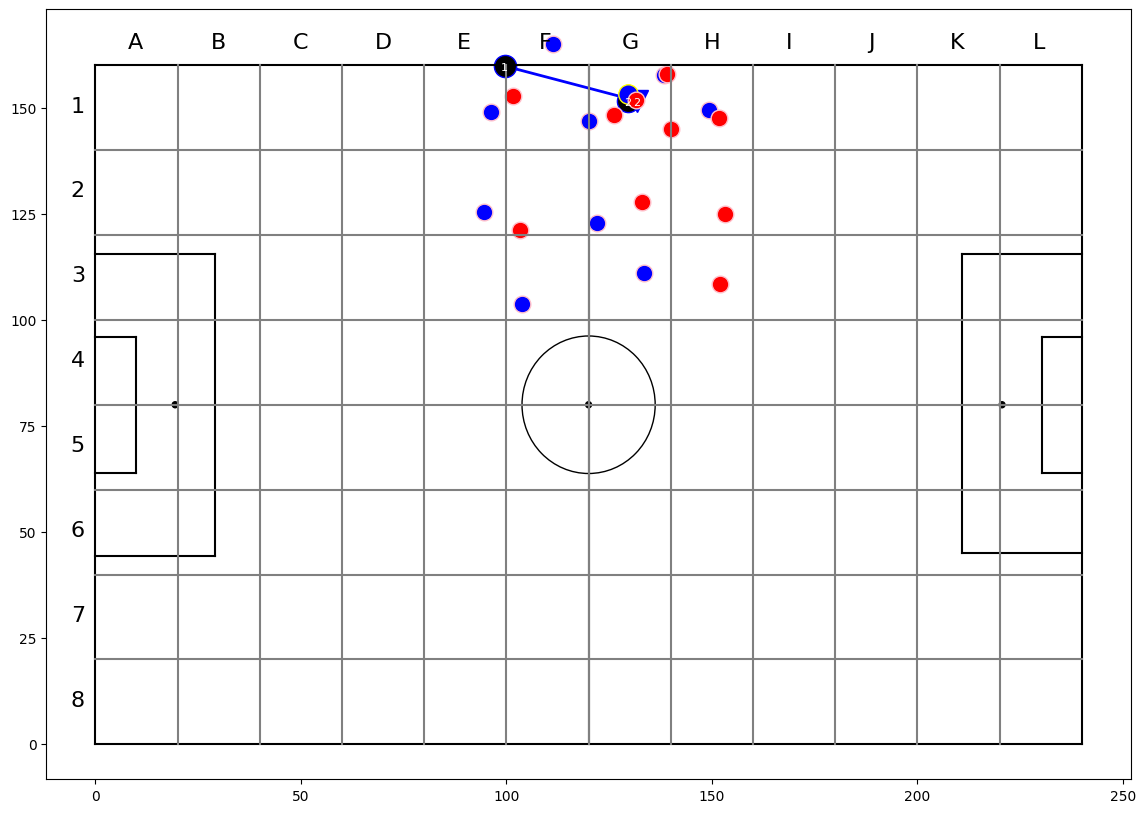

sequence 1
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:27:07.725>
2: Grzegorz Krychowiak (Clearance) <00:27:10.623>


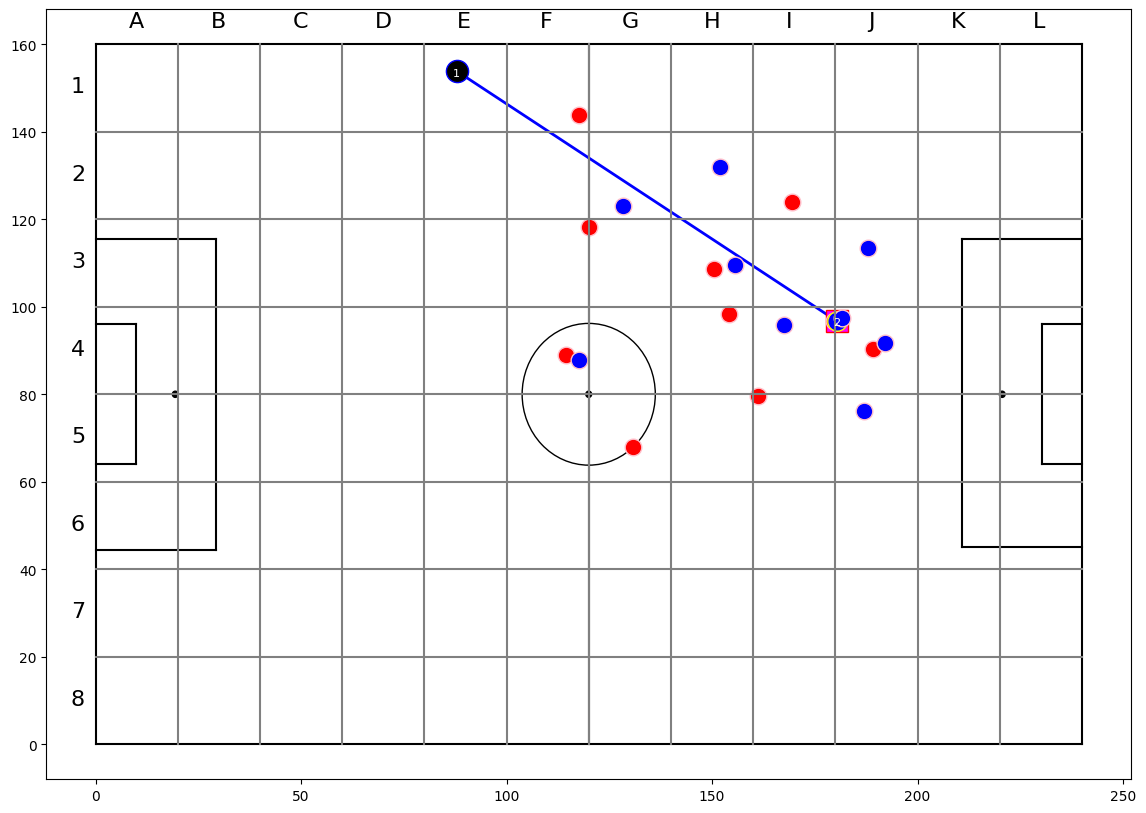

sequence 2
Team: Sweden
1: Robin Olsen (Pass) <00:43:43.529>
2: Sebastian Larsson (Ball Receipt*) <00:43:47.215>
2: Sebastian Larsson (Duel) <00:43:47.215>
3: Tymoteusz Puchacz (Pass) <00:43:47.215>
4: Sebastian Larsson (Block) <00:43:47.295>


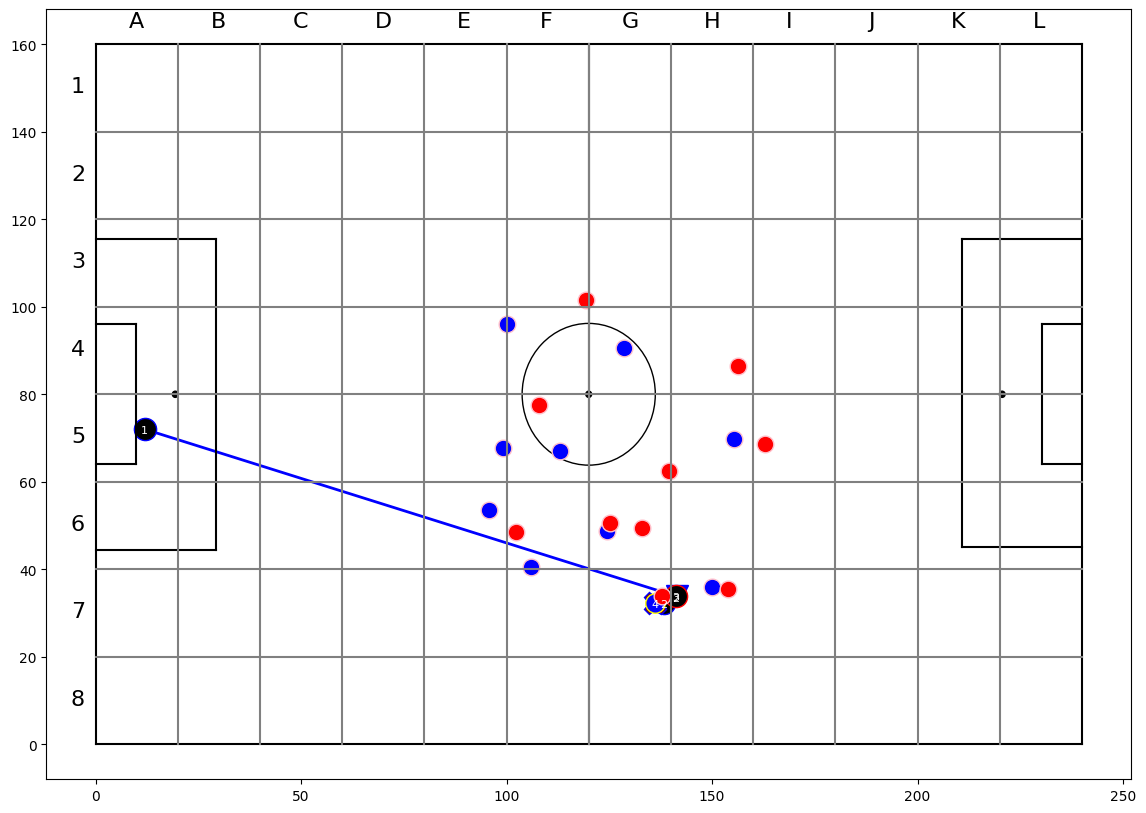

In [3]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_sweden_1 = find_fast_actions(sequences=sequences, team='Sweden', start_team=start_team, half=1)

for i, s in enumerate(fast_attact_sweden_1):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

sequence 0
Team: Poland
1: Kamil Glik (Pass) <00:24:05.478>
2: Robert Lewandowski (Ball Receipt*) <00:24:07.295>
2: Robert Lewandowski (Pass) <00:24:07.319>
3: Piotr Zieliński (Ball Receipt*) <00:24:08.362>
3: Piotr Zieliński (Carry) <00:24:08.362>


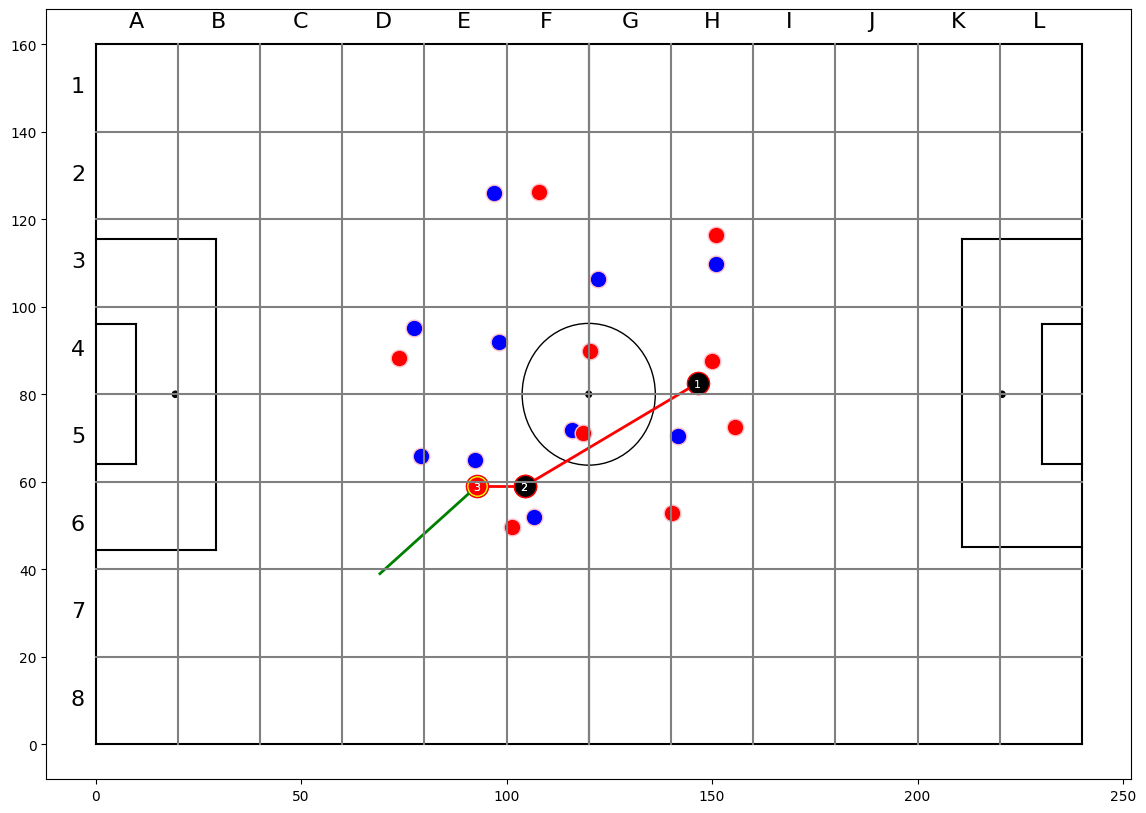

In [4]:
fast_attact_poland_1 = find_fast_actions(sequences=sequences, team='Poland', start_team=start_team, half=1)

for i, s in enumerate(fast_attact_poland_1):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

sequence 0
Team: Sweden
1: Robin Olsen (Pass) <00:07:27.410>
2: Alexander Isak (Duel) <00:07:31.294>


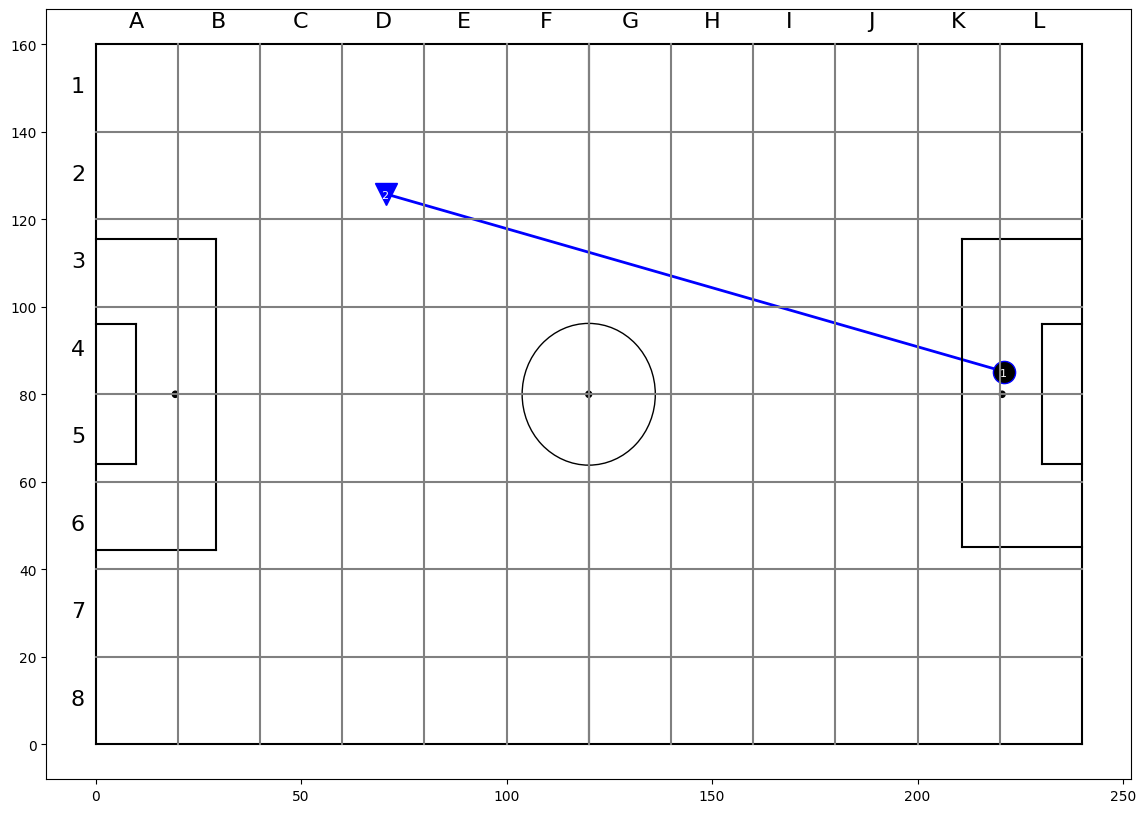

sequence 1
Team: Sweden
1: Robin Olsen (Pass) <00:17:44.687>
2: Alexander Isak (Foul Committed) <00:17:48.441>
3: Grzegorz Krychowiak (Foul Won) <00:17:48.441>


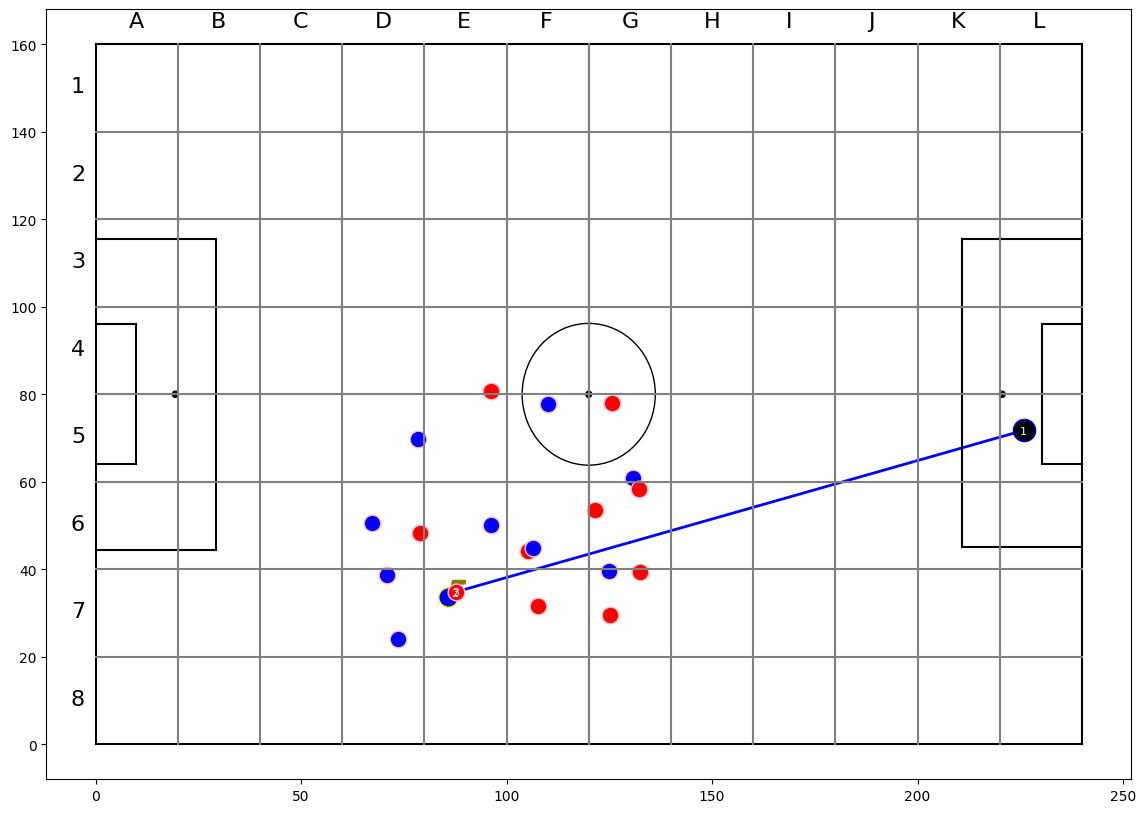

sequence 2
Team: Sweden
1: Albin Ekdal (Pass) <00:34:04.170>
2: Dejan Kulusevski (Ball Receipt*) <00:34:05.994>
2: Dejan Kulusevski (Carry) <00:34:05.994>
2: Dejan Kulusevski (Pass) <00:34:06.129>
3: Marcus Berg (Ball Receipt*) <00:34:07.089>
3: Marcus Berg (Carry) <00:34:07.089>
3: Marcus Berg (Dispossessed) <00:34:08.390>


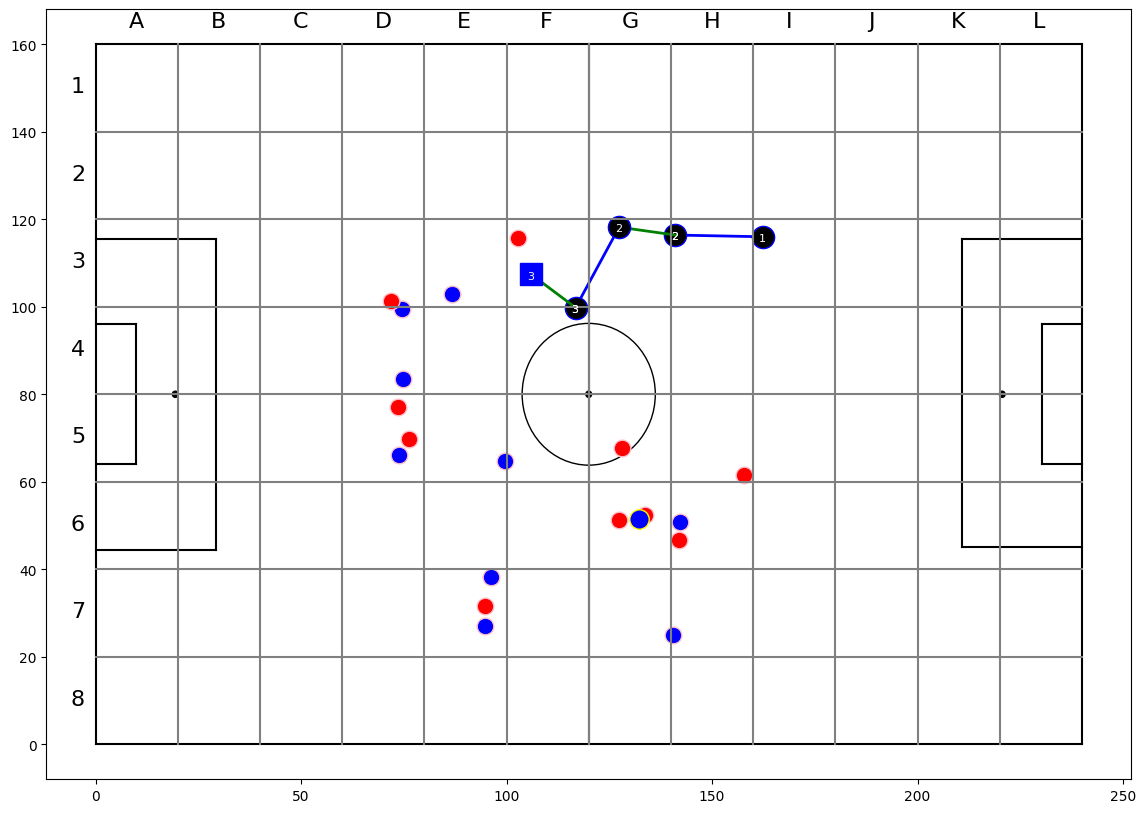

sequence 3
Team: Sweden
1: Robin Olsen (Pass) <00:45:46.196>
2: Marcus Berg (Ball Receipt*) <00:45:49.725>
2: Marcus Berg (Pass) <00:45:49.735>
3: Przemysław Frankowski (Duel) <00:45:49.735>
4: Dejan Kulusevski (Ball Receipt*) <00:45:51.074>


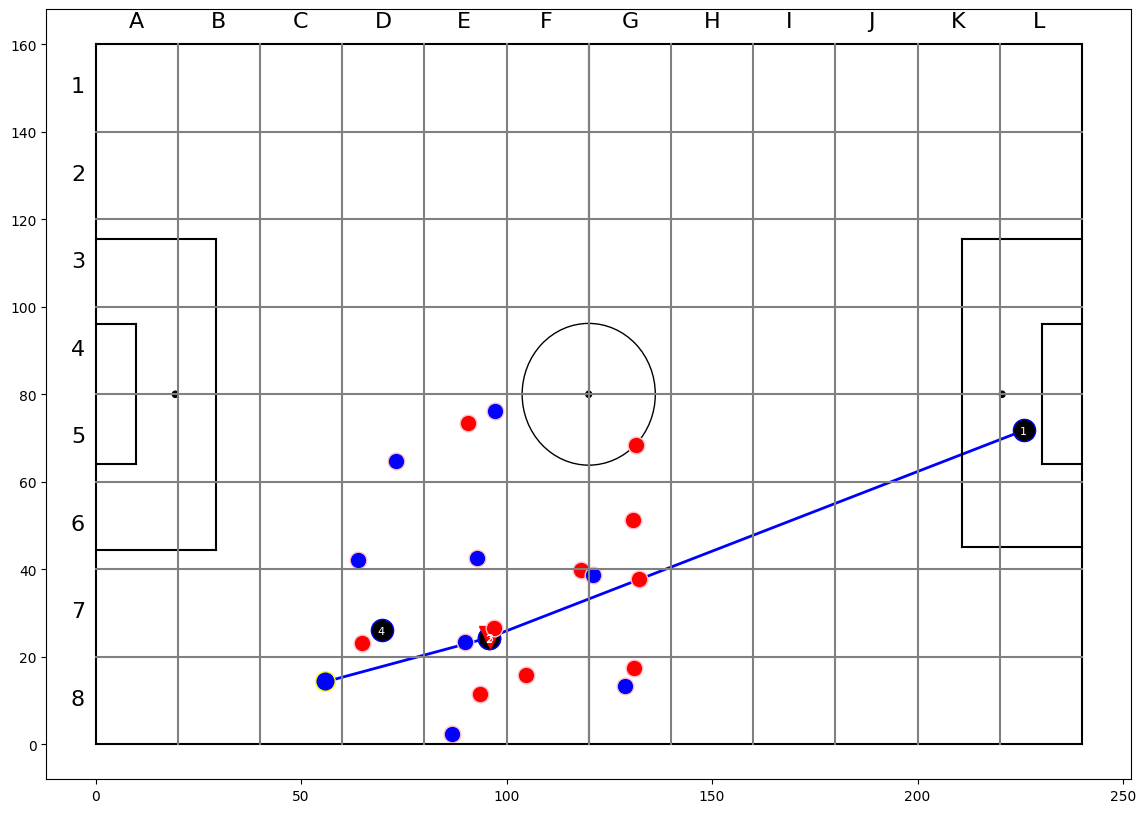

In [5]:
fast_attact_sweden_2 = find_fast_actions(sequences=sequences, team='Sweden', start_team=start_team, half=2)

for i, s in enumerate(fast_attact_sweden_2):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

sequence 0
Team: Poland
1: Piotr Zieliński (Pass) <00:00:00.585>
2: Kamil Glik (Ball Receipt*) <00:00:02.113>
2: Kamil Glik (Carry) <00:00:02.113>
2: Kamil Glik (Pass) <00:00:03.811>
3: Robert Lewandowski (Duel) <00:00:06.969>
4: Victor Nilsson Lindelöf (Pass) <00:00:06.969>
5: Sebastian Larsson (Ball Receipt*) <00:00:09.248>
5: Sebastian Larsson (Pass) <00:00:09.248>


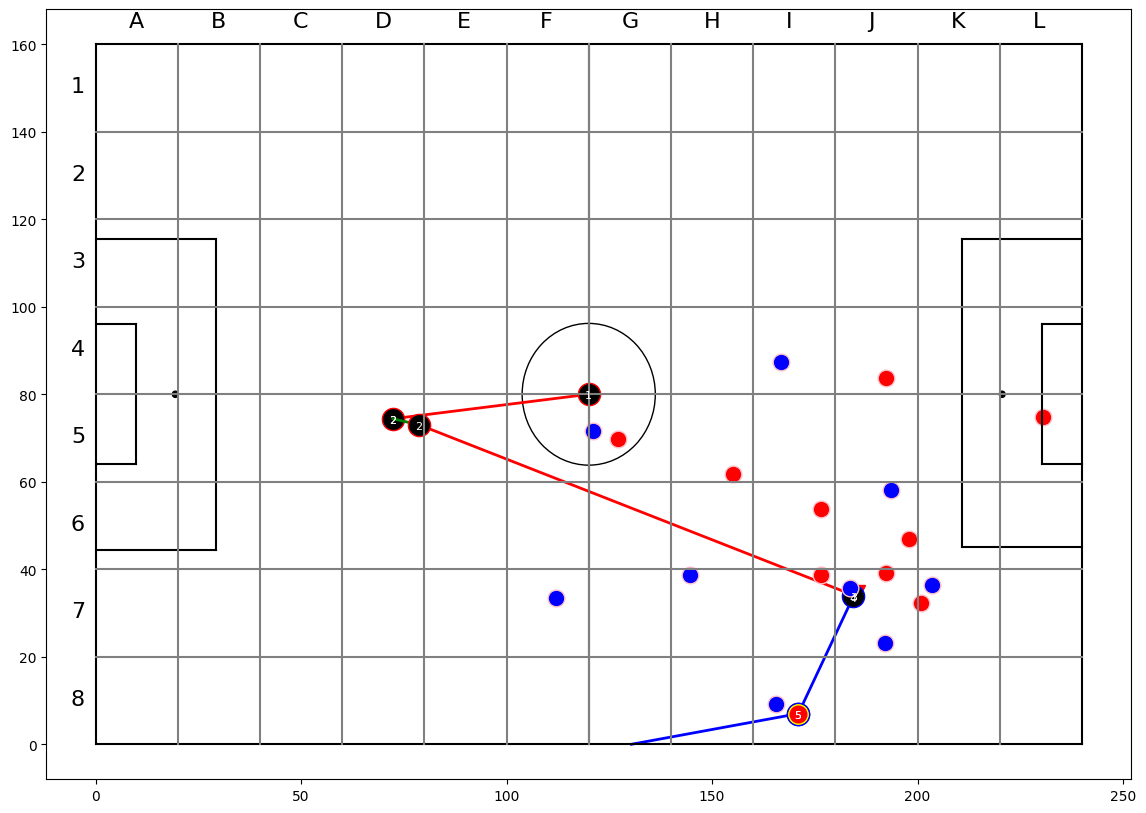

sequence 1
Team: Poland
1: Jan Bednarek (Ball Recovery) <00:03:18.133>
1: Jan Bednarek (Carry) <00:03:18.133>
1: Jan Bednarek (Pass) <00:03:19.179>
2: Przemysław Frankowski (Ball Receipt*) <00:03:20.861>
2: Przemysław Frankowski (Carry) <00:03:20.861>
2: Przemysław Frankowski (Pass) <00:03:24.993>
3: Piotr Zieliński (Ball Receipt*) <00:03:25.839>
3: Piotr Zieliński (Carry) <00:03:25.839>
3: Piotr Zieliński (Shot) <00:03:26.916>
4: Victor Nilsson Lindelöf (Block) <00:03:27.171>


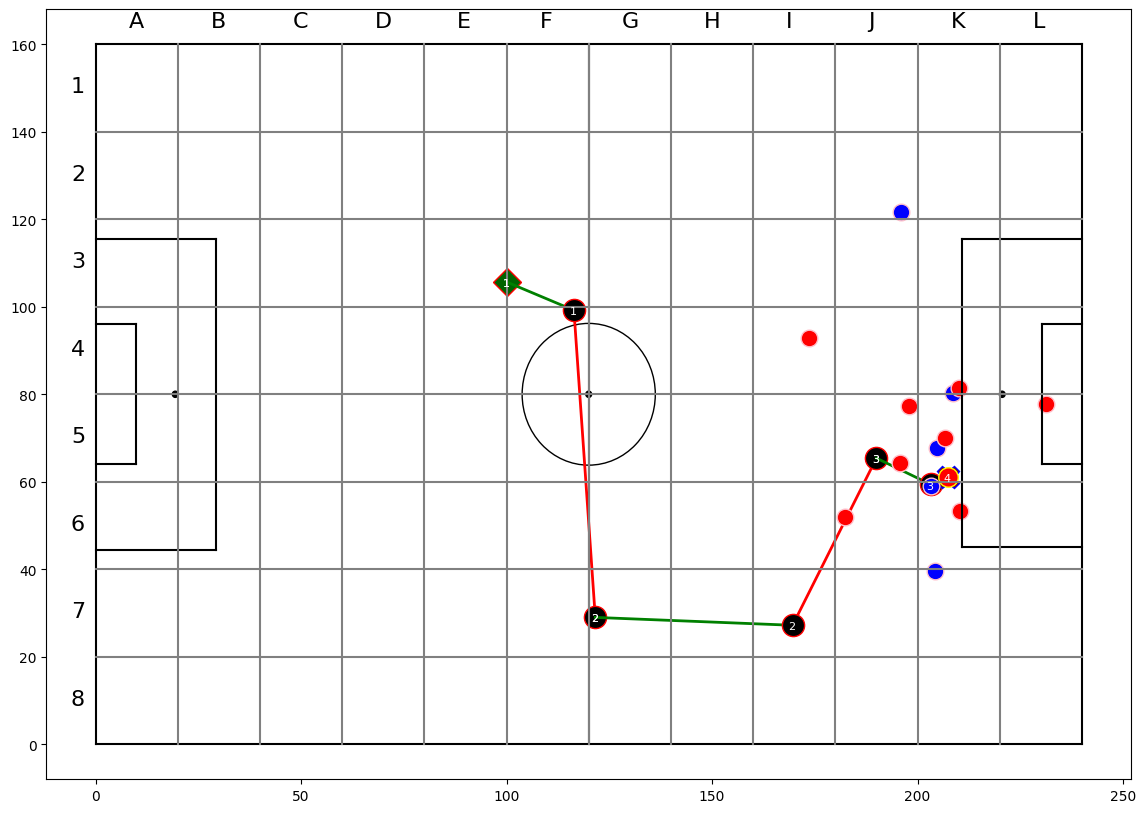

sequence 2
Team: Poland
1: Grzegorz Krychowiak (Ball Recovery) <00:10:14.522>
1: Grzegorz Krychowiak (Carry) <00:10:14.522>
1: Grzegorz Krychowiak (Pass) <00:10:15.864>
2: Marcus Andreas Danielsson (Pass) <00:10:20.119>
3: Emil Peter Forsberg (Ball Receipt*) <00:10:21.767>
4: Mateusz Andrzej Klich (Pass) <00:10:21.767>
5: Karol Świderski (Ball Receipt*) <00:10:22.530>
5: Karol Świderski (Carry) <00:10:22.530>
5: Karol Świderski (Miscontrol) <00:10:22.580>


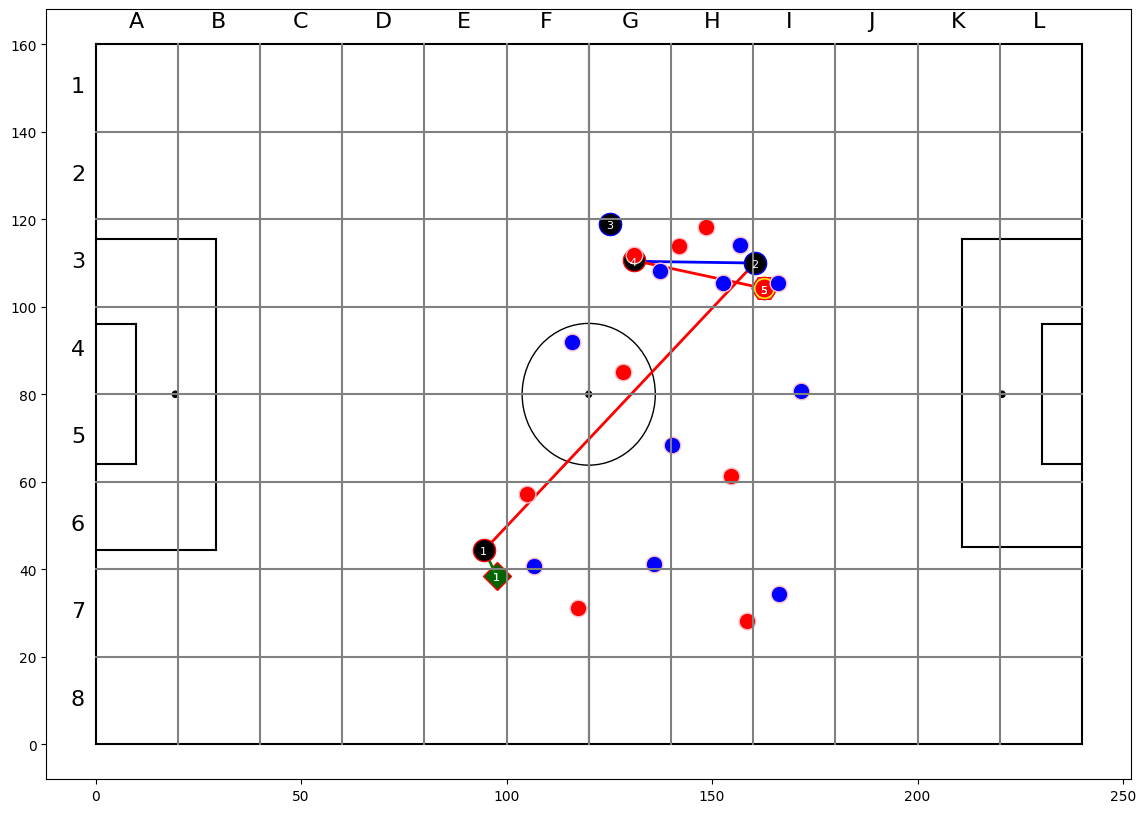

sequence 3
Team: Poland
1: Kamil Jóźwiak (Duel) <00:15:09.908>
2: Piotr Zieliński (Ball Recovery) <00:15:11.780>
2: Piotr Zieliński (Carry) <00:15:11.780>
2: Piotr Zieliński (Pass) <00:15:13.019>
3: Robert Lewandowski (Ball Receipt*) <00:15:17.271>
3: Robert Lewandowski (Carry) <00:15:17.271>
3: Robert Lewandowski (Shot) <00:15:19.870>


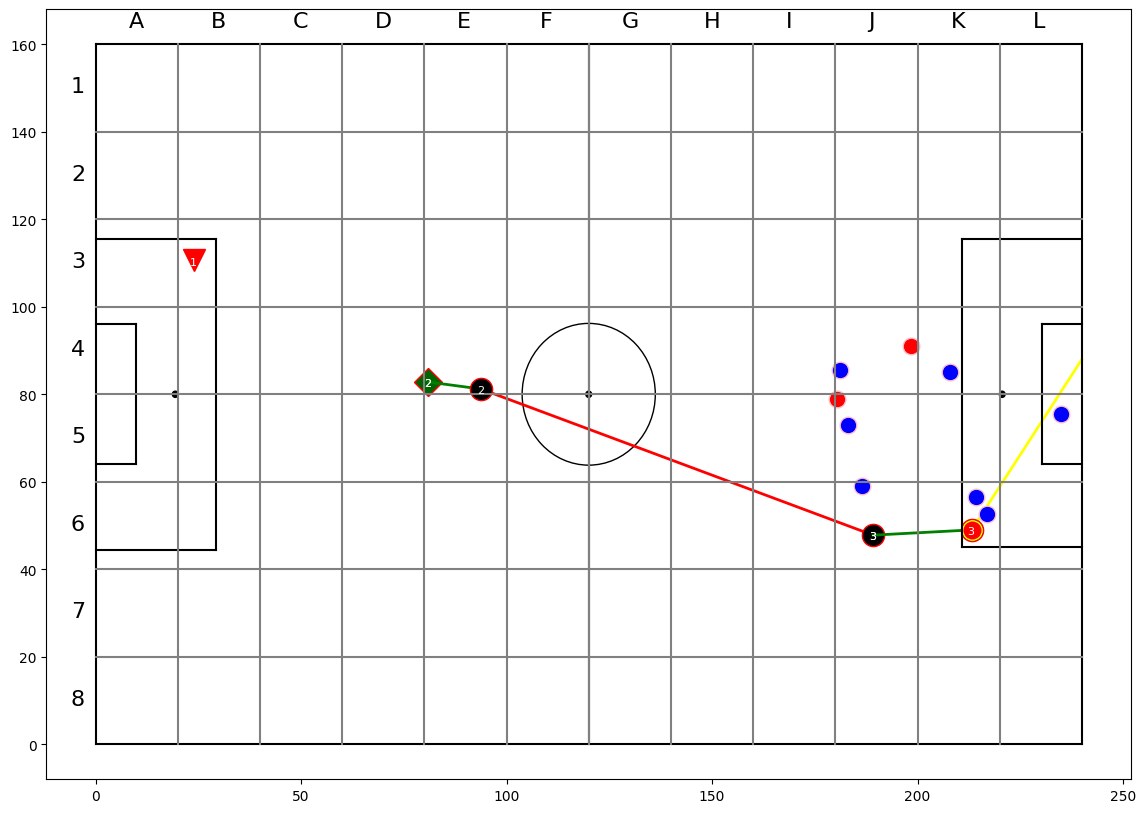

sequence 4
Team: Poland
1: Jan Bednarek (Ball Recovery) <00:45:51.074>
1: Jan Bednarek (Carry) <00:45:51.074>
1: Jan Bednarek (Pass) <00:45:52.105>
2: Robert Lewandowski (Ball Receipt*) <00:45:53.870>
2: Robert Lewandowski (Carry) <00:45:53.870>
2: Robert Lewandowski (Pass) <00:45:53.911>
3: Karol Świderski (Ball Receipt*) <00:45:54.269>


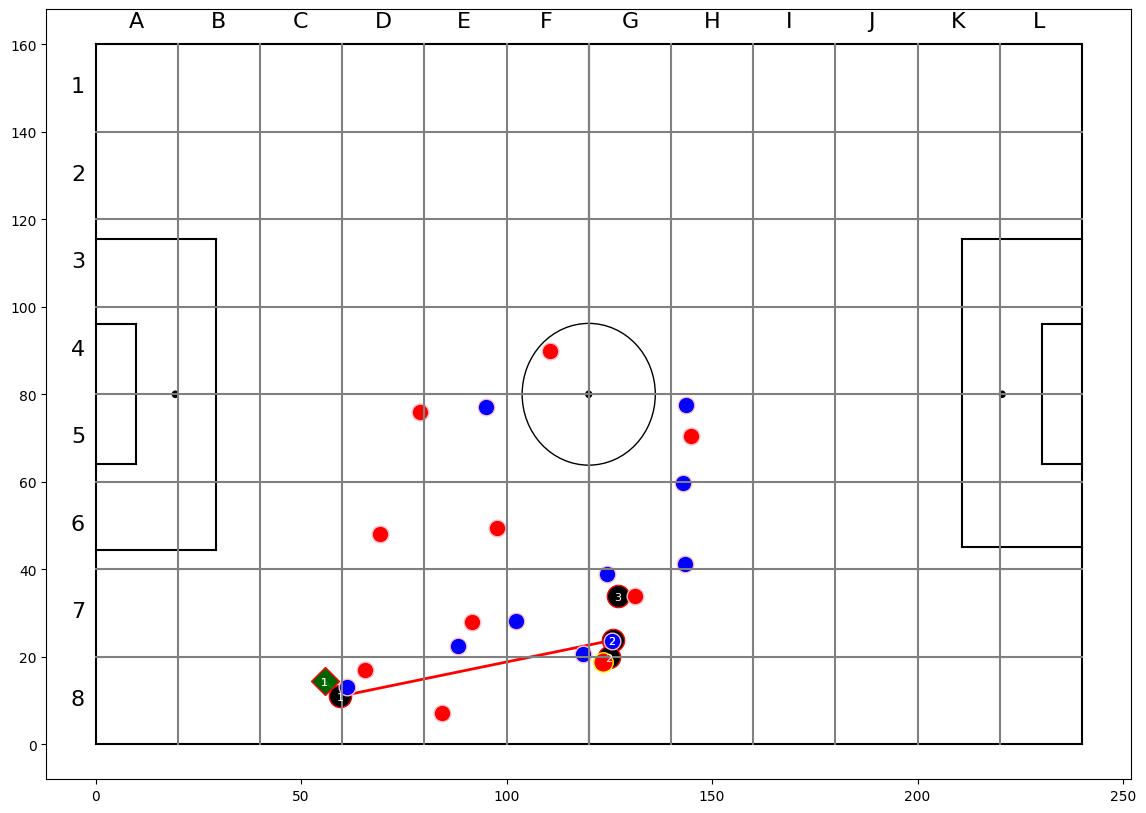

In [7]:
fast_attact_poland_2 = find_fast_actions(max_timestamp=10000, sequences=sequences, team='Poland', start_team=start_team, half=2)

for i, s in enumerate(fast_attact_poland_2):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)